# 군집분석

한 기업이 해킹을 당해서 우리에게 도움을 요청했습니다! 다행스럽게도 그 기업의 포렌식 기술자들은 session time, location, wpm typing speed 등과 같은 해킹에 대한 귀중한 정보를 수집했습니다. 담당 포렌식 기술자와의 회의에서 듣기로는 해커들이 서버에 접속하는데에 사용한 각 세션의 메타 데이터들을 수집한 것이라고 합니다.

다음은 수집된 데이터입니다

- Session_Connection_Time : 세션이 지속된 시간(분)입니다.
- Bytes Transferred : 세션 중에 전송된 데이터 용량(MB)입니다.
- Kali_Trace_Used : 해커의 Kali Linux 사용 여부입니다.
- Servers_Corrupted : 공격으로 손상된 서버 수 입니다.
- Pages_Corrupted : 무단으로 접근한 페이지 수 입니다.
- Location : 공격이 시작된 위치입니다.(해커들이 VPN을 사용했기 때문에 아마 쓸모가 없을 것 같습니다.)
- WPM_Typing_Speed : 세션 로그를 기준으로 예상한 타이핑 속도입니다.

이 회사에서는 3명의 해커를 의심 중입니다. 2명의 해커는 어느정도 확신하고 있지만 세 번째 해커가 해킹에 연루되었는지 아직 확실하지 않습니다. 우리에게 의뢰한 부분은 이 부분입니다. 즉, 이번 해킹 사건에서 2명이 공격을 한 것인지 3명이 공격을 한 것인지 분석해달라고 합니다. 확실하지는 않지만 클러스터링으로 알아 볼 수 있을 것 같습니다.

마지막으로 한가지 알려드릴 중요한 사실은, 각 해커들의 공격횟수는 거의 동일합니다. 예를 들어, 총 공격 횟수가 120번 이었다면, 60건씩 2명이 공격을 했거나 3명이 40건씩 공격을 했다는 말입니다. 데이터는 hack_data.csv 파일로 전달해 드리겠습니다.

In [14]:
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

# 데이터 탐색

In [2]:
df = pd.read_csv("./과제/군집/hack_data.csv")

In [3]:
df.head()

,Session_Connection_Time,Bytes Transferred,Kali_Trace_Used,Servers_Corrupted,Pages_Corrupted,Location,WPM_Typing_Speed
0,8.0,391.09,1,2.96,7.0,Slovenia,72.37
1,20.0,720.99,0,3.04,9.0,British Virgin Islands,69.08
2,31.0,356.32,1,3.71,8.0,Tokelau,70.58
3,2.0,228.08,1,2.48,8.0,Bolivia,70.80
4,20.0,408.50,0,3.57,8.0,Iraq,71.28


In [4]:
df.shape

(334, 7)

In [5]:
df.dtypes

Session_Connection_Time    float64
Bytes Transferred          float64
Kali_Trace_Used              int64
Servers_Corrupted          float64
Pages_Corrupted            float64
Location                    object
WPM_Typing_Speed           float64
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 334 entries, 0 to 333
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Session_Connection_Time  334 non-null    float64
 1   Bytes Transferred        334 non-null    float64
 2   Kali_Trace_Used          334 non-null    int64  
 3   Servers_Corrupted        334 non-null    float64
 4   Pages_Corrupted          334 non-null    float64
 5   Location                 334 non-null    object 
 6   WPM_Typing_Speed         334 non-null    float64
dtypes: float64(5), int64(1), object(1)
memory usage: 18.4+ KB


In [7]:
df.describe()

,Session_Connection_Time,Bytes Transferred,Kali_Trace_Used,Servers_Corrupted,Pages_Corrupted,WPM_Typing_Speed
count,334.000000,334.000000,334.000000,334.000000,334.000000,334.000000
mean,30.008982,607.245269,0.511976,5.258503,10.838323,57.342395
std,14.088201,286.335932,0.500607,2.301907,3.063526,13.411063
min,1.000000,10.000000,0.000000,1.000000,6.000000,40.000000
25%,18.000000,372.200000,0.000000,3.122500,8.000000,44.127500
50%,31.000000,601.650000,1.000000,5.285000,10.500000,57.840000
75%,42.000000,843.702500,1.000000,7.400000,14.000000,70.577500
max,60.000000,1330.500000,1.000000,10.000000,15.000000,75.000000


In [8]:
df["Location"].value_counts()

Location
United States Virgin Islands    6
Guinea-Bissau                   5
Czech Republic                  5
Mauritania                      5
Trinidad and Tobago             4
                               ..
Austria                         1
Kuwait                          1
Samoa                           1
Mexico                          1
Canada                          1
Name: count, Length: 181, dtype: int64

In [9]:
# 의뢰인의 도메인 - Location 삭제 : 해커들이 vpn을 사용했기 때문에 불필요
df = df.drop("Location", axis = 1)

In [10]:
df.head()

,Session_Connection_Time,Bytes Transferred,Kali_Trace_Used,Servers_Corrupted,Pages_Corrupted,WPM_Typing_Speed
0,8.0,391.09,1,2.96,7.0,72.37
1,20.0,720.99,0,3.04,9.0,69.08
2,31.0,356.32,1,3.71,8.0,70.58
3,2.0,228.08,1,2.48,8.0,70.80
4,20.0,408.50,0,3.57,8.0,71.28


- 모든 컬럼에 결측치 없음을 확인

- 컬럼마다 데이터의 분포가 다양함
    - 스케일링 필요할 수 있음

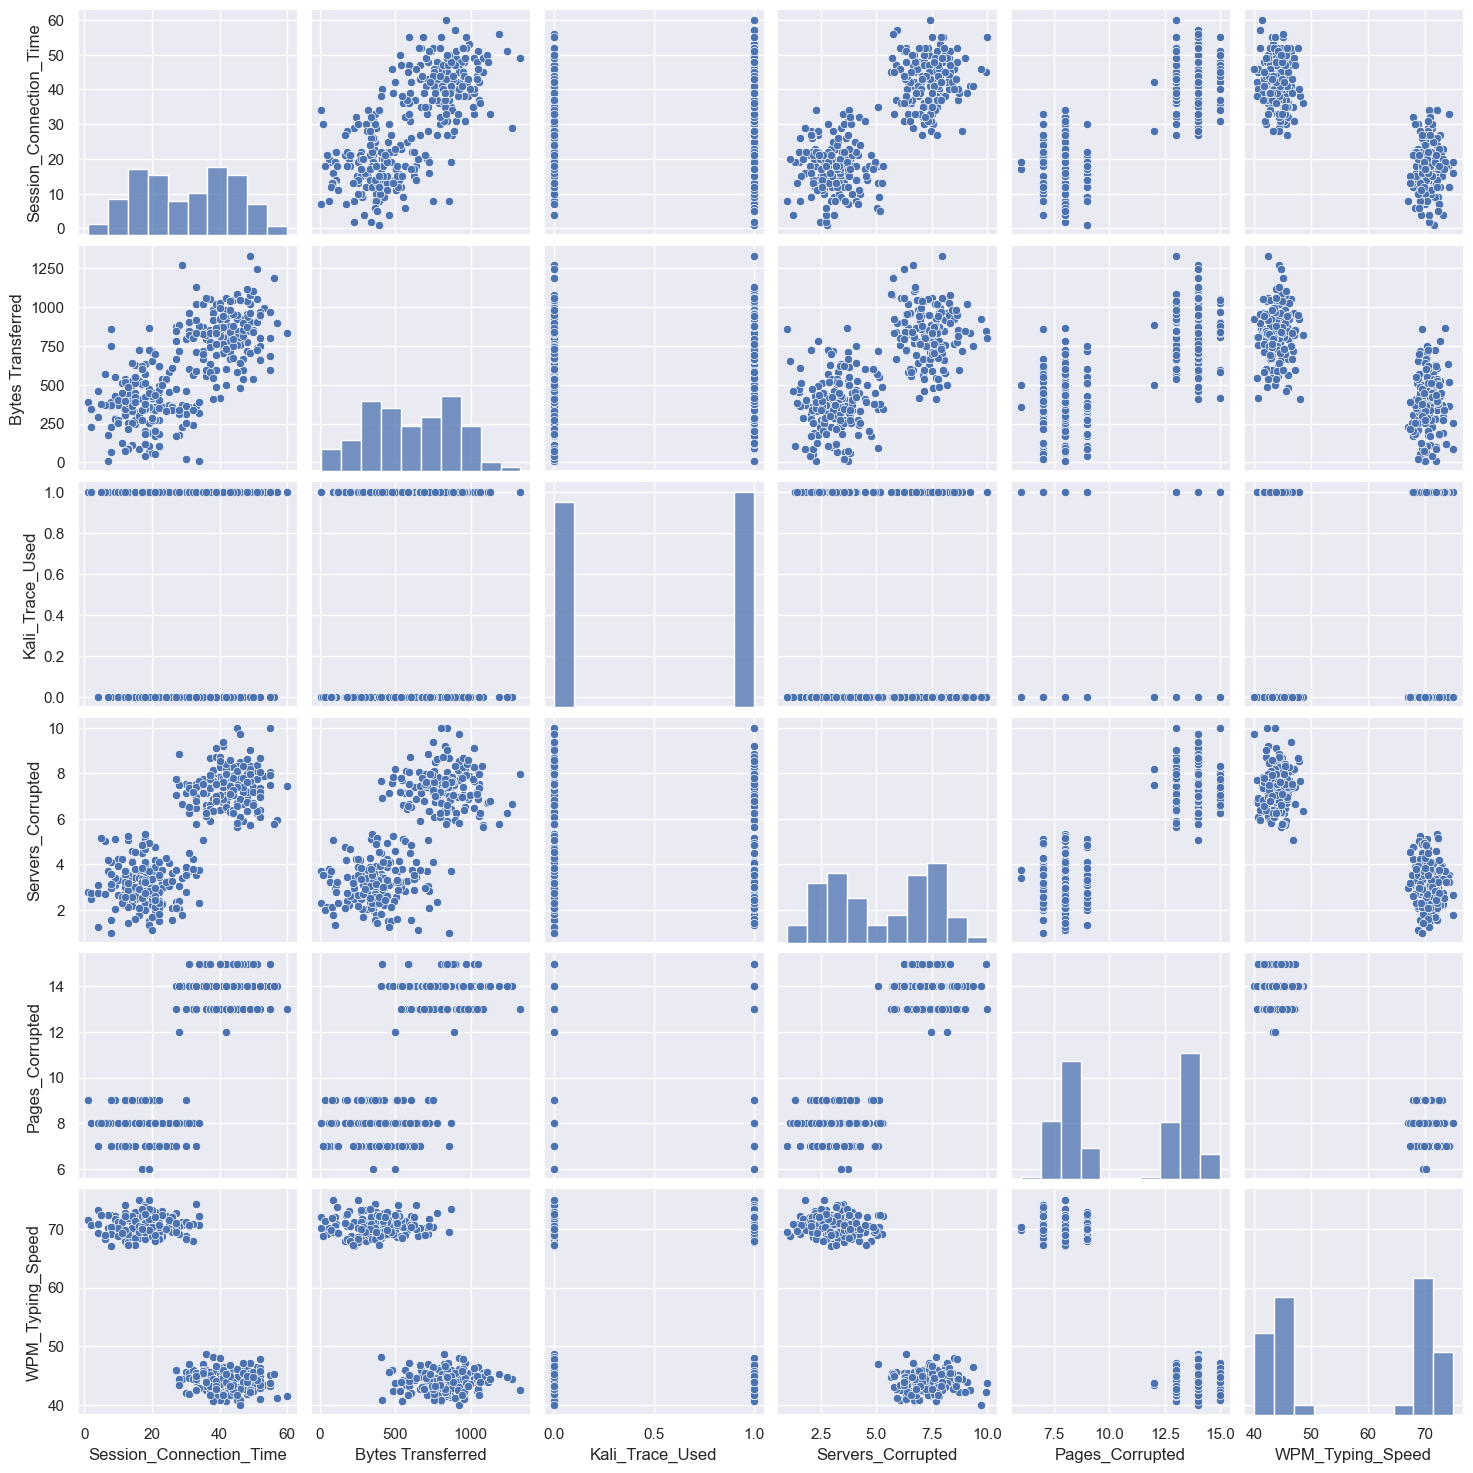

In [11]:
sns.set(style = "darkgrid")
sns.pairplot(df)
plt.show()

- 시각화 결과 전반적으로 2개의 군집으로 나뉘어 2인의 해커 공격으로 추정

# 스케일링

In [12]:
ss = StandardScaler()
scaled_df = ss.fit_transform(df)

# 모델 학습

In [15]:
for k in range(2, 4):
    km = KMeans(n_clusters = k, random_state = 26)
    km.fit(scaled_df)
    print(f"k 값이 {k}일 때")
    print(np.unique(km.labels_, return_counts = True))
    print("-" * 80)

k 값이 2일 때
(array([0, 1]), array([167, 167], dtype=int64))
--------------------------------------------------------------------------------
k 값이 3일 때
(array([0, 1, 2]), array([ 84, 167,  83], dtype=int64))
--------------------------------------------------------------------------------


## pca 차원축소를 통한 시각화

In [16]:
pca = PCA(n_components = 2)

In [17]:
df_pca = pca.fit_transform(scaled_df)
df_pca = pd.DataFrame(df_pca)
df_pca.columns = ["pc1", "pc2"]

In [18]:
df_pca.head()

,pc1,pc2
0,-2.530631,-1.053229
1,-1.295176,0.931575
2,-1.506419,-1.003917
3,-2.839759,-1.021613
4,-1.872074,0.970304


In [19]:
# 주성분 확인
pca.components_

array([[ 0.43617511,  0.4135031 ,  0.02404166,  0.45028217,  0.46405374,
        -0.46913597],
       [ 0.0137742 , -0.04633696, -0.99767421,  0.01803537,  0.03596926,
        -0.02627294]])

In [20]:
df.columns

Index(['Session_Connection_Time', 'Bytes Transferred', 'Kali_Trace_Used',
       'Servers_Corrupted', 'Pages_Corrupted', 'WPM_Typing_Speed'],
      dtype='object')

In [21]:
# 설명된 분산 확인
np.sum(pca.explained_variance_ratio_)

0.8906380969597125

In [22]:
km2 = KMeans(n_clusters = 2, random_state = 26)
km2.fit(df_pca)

KMeans(n_clusters=2, random_state=26)

<Figure size 640x480 with 0 Axes>

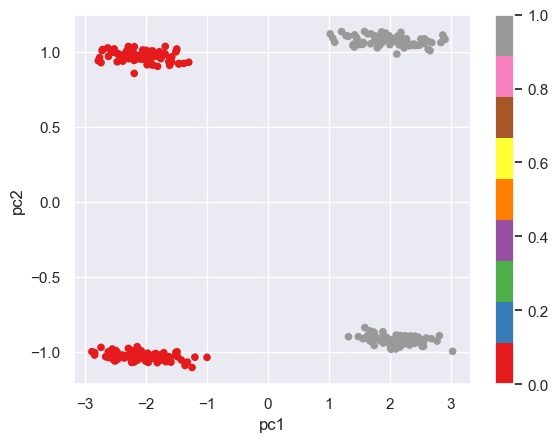

In [23]:
plt.figure()
df_pca.plot(kind = "scatter", x = "pc1", y = "pc2", c = km2.labels_, colormap = "Set1")
plt.show()

In [24]:
km3 = KMeans(n_clusters = 3, random_state = 26)
km3.fit(df_pca)

KMeans(n_clusters=3, random_state=26)

<Figure size 640x480 with 0 Axes>

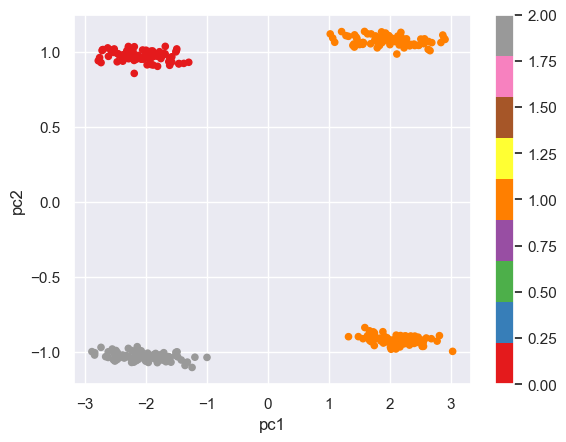

In [25]:
plt.figure()
df_pca.plot(kind = "scatter", x = "pc1", y = "pc2", c = km3.labels_, colormap = "Set1")
plt.show()